<a href="https://colab.research.google.com/github/ranimiftah12345678/ML_22_Ranimiftah/blob/main/JS07/TUGAS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('/content/CC_Customer_Dataset.csv')
df.columns = df.columns.str.strip()

print("Ukuran data:", df.shape)
display(df.head())
print(df.isna().sum())

col_limit = [c for c in df.columns if c.lower() == 'avg_credit_limit'][0]
col_card  = [c for c in df.columns if c.lower() in ('total_credit_cards', 'total_credit_card')][0]
print("Kolom dipakai:", col_limit, "|", col_card)

Ukuran data: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64
Kolom dipakai: Avg_Credit_Limit | Total_Credit_Cards


## Soal 1 - Scatterplot Avg_Credit_Limit vs Total_Credit_Cards

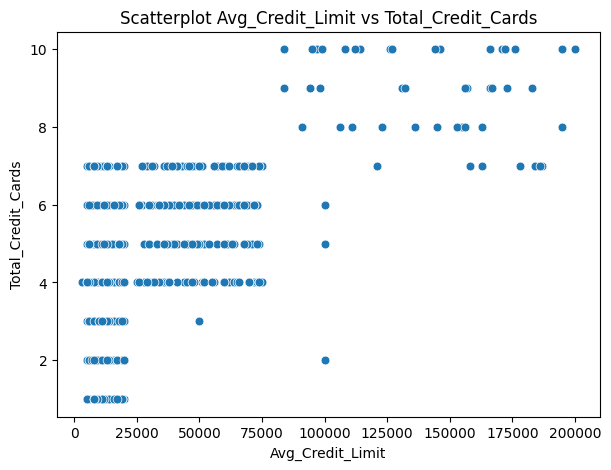

Korelasi Pearson : 0.609
Korelasi Spearman: 0.518


In [2]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x=col_limit, y=col_card, s=40)
plt.title(f"Scatterplot {col_limit} vs {col_card}")
plt.show()

print("Korelasi Pearson :", round(df[col_limit].corr(df[col_card], method='pearson'), 3))
print("Korelasi Spearman:", round(df[col_limit].corr(df[col_card], method='spearman'), 3))

Korelasi Pearson antara Avg_Credit_Limit dan Total_Credit_Cards sebesar **0,609** dan korelasi Spearman **0,518**. Nilai ini menunjukkan hubungan positif yang hanya **sedang**, jauh dari hubungan linier sempurna (±1).

Pada scatterplot, titik-titik tidak membentuk satu garis lurus. Jumlah kartu bersifat diskrit (1-10) sehingga titik tersusun dalam kolom-kolom vertikal, dan variasi limit kredit melebar pada jumlah kartu yang besar. Nasabah dengan 8-10 kartu memiliki limit rata-rata sekitar 137 ribu-140 ribu, sementara nasabah dengan 1-3 kartu hanya sekitar 11 ribu-13 ribu. Kenaikan limit tidak bertambah secara bertahap, melainkan melonjak pada kelompok nasabah tertentu.

Dengan demikian sebaran data **tidak dapat dikatakan linier**. Pola ini justru mengindikasikan adanya kelompok-kelompok nasabah (klaster) dengan karakteristik berbeda.

## Soal 2 - K-Means dan Elbow Method
Kedua variabel distandarisasi (StandardScaler) agar limit kredit yang bernilai puluhan ribu tidak mendominasi jumlah kartu yang bernilai 1-10.

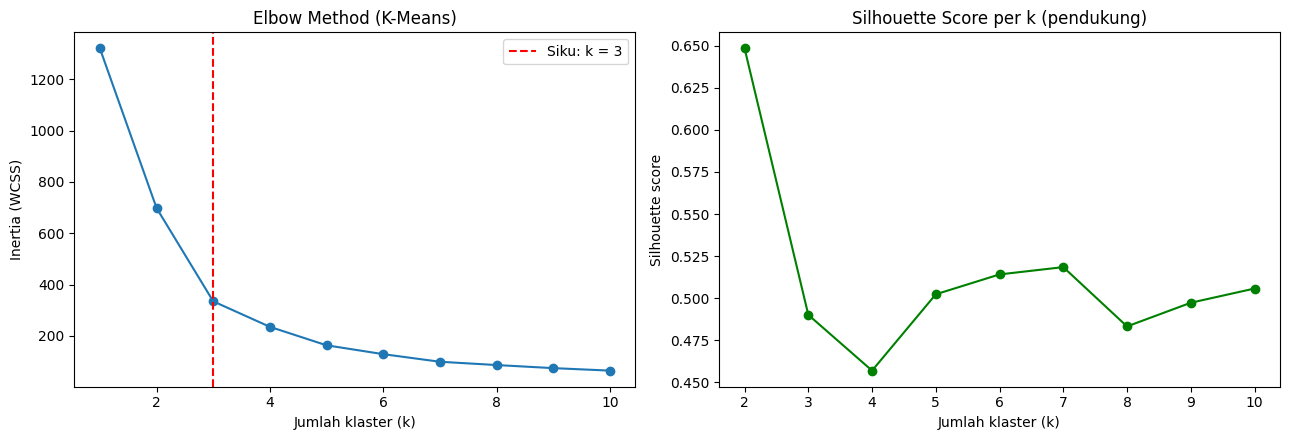

Inertia per k   : [1320.0, 698.3, 334.7, 235.4, 163.5, 129.0, 99.4, 86.5, 74.5, 64.8]
Silhouette per k: [np.float64(0.648), np.float64(0.49), np.float64(0.457), np.float64(0.502), np.float64(0.514), np.float64(0.518), np.float64(0.483), np.float64(0.497), np.float64(0.506)]
k terbaik (elbow): 3


In [3]:
X2 = df[[col_limit, col_card]]
X2_s = StandardScaler().fit_transform(X2)

K_range = range(1, 11)
inertia, sil_km = [], []
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X2_s)
    inertia.append(km.inertia_)
    sil_km.append(silhouette_score(X2_s, km.labels_) if k > 1 else np.nan)

def cari_siku(x, y):
    """Titik siku = titik dengan jarak terjauh ke garis penghubung titik awal-akhir."""
    x = np.array(x, float); y = np.array(y, float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y - y.min()) / (y.max() - y.min())
    x1, y1, x2, y2 = xn[0], yn[0], xn[-1], yn[-1]
    jarak = np.abs((y2 - y1) * xn - (x2 - x1) * yn + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)
    return int(np.argmax(jarak))

idx = cari_siku(list(K_range), inertia)
k_terbaik = list(K_range)[idx]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(K_range, inertia, marker='o')
ax[0].axvline(k_terbaik, color='red', linestyle='--', label=f'Siku: k = {k_terbaik}')
ax[0].set_title("Elbow Method (K-Means)")
ax[0].set_xlabel("Jumlah klaster (k)"); ax[0].set_ylabel("Inertia (WCSS)")
ax[0].legend()

ax[1].plot(list(K_range)[1:], sil_km[1:], marker='o', color='green')
ax[1].set_title("Silhouette Score per k (pendukung)")
ax[1].set_xlabel("Jumlah klaster (k)"); ax[1].set_ylabel("Silhouette score")
plt.tight_layout(); plt.show()

print("Inertia per k   :", [round(v, 1) for v in inertia])
print("Silhouette per k:", [round(v, 3) for v in sil_km[1:]])
print("k terbaik (elbow):", k_terbaik)

Nilai inertia (WCSS) untuk k = 1 hingga 10 adalah: 1320,0; 698,3; 334,7; 235,4; 163,5; 129,0; 99,4; 86,5; 74,5; 64,8.

Penurunan inertia sangat tajam dari k = 1 ke k = 2 (-621,7) dan dari k = 2 ke k = 3 (-363,6). Setelah k = 3 penurunannya melandai (k = 3 ke k = 4 hanya -99,3 dan seterusnya semakin kecil). Titik tekukan (siku) terjadi pada **k = 3**, karena penambahan klaster setelahnya hanya memberikan perbaikan kecil (diminishing returns) dan menambah kompleksitas tanpa membuat klaster jauh lebih kompak.

Sebagai pendukung, silhouette score tertinggi memang berada di k = 2 (0,648), tetapi dua klaster terlalu kasar untuk segmentasi nasabah. Pada k = 3 silhouette tetap cukup baik (0,490) dan memberi segmentasi yang lebih bermakna. Maka dipilih **k = 3**.

## Soal 3 - Scatterplot Hasil K-Means (k = 3)

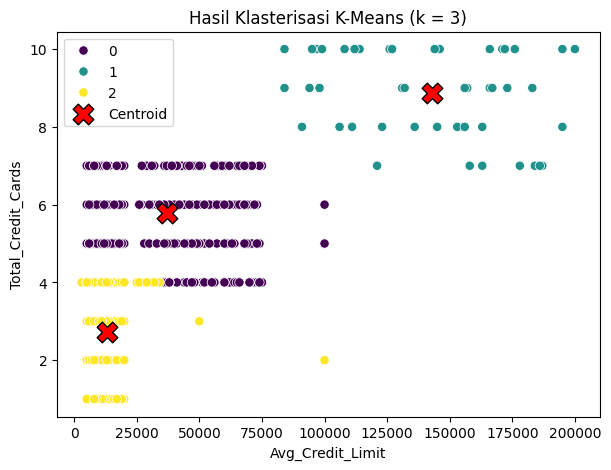

Cluster_KMeans
0    330
1     48
2    282
Name: count, dtype: int64
                Avg_Credit_Limit  Total_Credit_Cards
Cluster_KMeans                                      
0                        37160.6                 5.8
1                       142750.0                 8.9
2                        13134.8                 2.7
Silhouette K-Means: 0.4901


In [4]:
kmeans = KMeans(n_clusters=k_terbaik, n_init=10, random_state=42)
df['Cluster_KMeans'] = kmeans.fit_predict(X2_s)

pusat = StandardScaler().fit(X2).inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x=col_limit, y=col_card, hue='Cluster_KMeans',
                palette='viridis', s=45)
plt.scatter(pusat[:, 0], pusat[:, 1], c='red', marker='X', s=220,
            edgecolor='black', label='Centroid')
plt.title(f"Hasil Klasterisasi K-Means (k = {k_terbaik})")
plt.legend()
plt.show()

print(df['Cluster_KMeans'].value_counts().sort_index())
print(df.groupby('Cluster_KMeans')[[col_limit, col_card]].mean().round(1))
print("Silhouette K-Means:", round(silhouette_score(X2_s, df['Cluster_KMeans']), 4))

Hasil klasterisasi membagi nasabah menjadi tiga kelompok:

| Klaster (jumlah anggota) | Rata-rata limit kredit | Rata-rata jumlah kartu | Interpretasi |
|---|---|---|---|
| 282 nasabah | ± 13.135 | ± 2,7 | Nasabah limit rendah dengan sedikit kartu |
| 330 nasabah | ± 37.161 | ± 5,8 | Nasabah limit menengah dengan kartu cukup banyak |
| 48 nasabah | ± 142.750 | ± 8,9 | Nasabah premium: limit sangat tinggi dan banyak kartu |

Silhouette score K-Means (k = 3) sebesar **0,490**. Klaster nasabah premium terpisah jelas di sisi kanan scatterplot. Klaster limit rendah dan menengah tumpang tindih pada sumbu limit kredit (keduanya mencakup rentang sekitar 3.000-100.000), sehingga pembeda utamanya adalah jumlah kartu: klaster limit rendah memiliki sekitar 2-3 kartu, sedangkan klaster limit menengah sekitar 5-6 kartu.

## Soal 4 - DBSCAN dengan Seluruh Variabel yang Dapat Digunakan
Kolom `Sl_No` dan `Customer Key` tidak diikutkan karena hanya identitas nasabah, bukan fitur. Seluruh fitur distandarisasi karena DBSCAN berbasis jarak.

In [5]:
kolom_id = [c for c in df.columns if c.lower().replace(' ', '_') in ('sl_no', 'customer_key')]
fitur = [c for c in df.select_dtypes(include=np.number).columns
         if c not in kolom_id and c != 'Cluster_KMeans']
print("Fitur untuk DBSCAN:", fitur)

X_all = df[fitur]
X_all_s = StandardScaler().fit_transform(X_all)

min_samples = 2 * len(fitur)      # aturan umum: 2 x jumlah dimensi
print("min_samples:", min_samples)

Fitur untuk DBSCAN: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
min_samples: 10


## Soal 5 - Menentukan Parameter Terbaik dengan Elbow (K-Distance Graph)
DBSCAN tidak memiliki parameter k seperti K-Means. Elbow method diterapkan pada **k-distance graph** untuk menentukan `eps`, dengan k = `min_samples`.

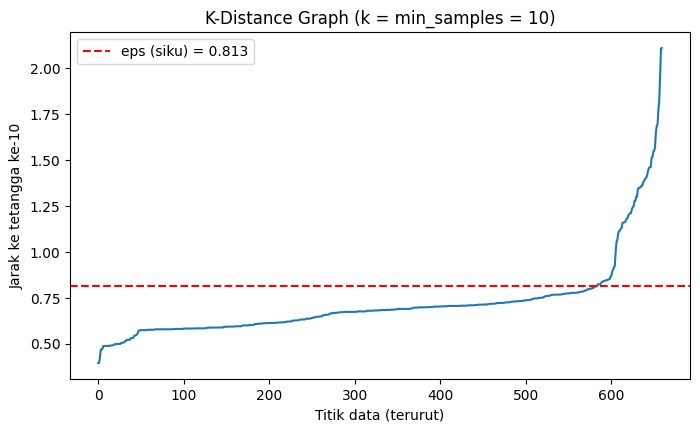

eps terbaik (siku): 0.8133


In [6]:
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_all_s)
jarak, _ = nn.kneighbors(X_all_s)
k_dist = np.sort(jarak[:, -1])

idx_siku = cari_siku(np.arange(len(k_dist)), k_dist)
eps_terbaik = float(k_dist[idx_siku])

plt.figure(figsize=(8, 4.5))
plt.plot(k_dist)
plt.axhline(eps_terbaik, color='red', linestyle='--', label=f'eps (siku) = {eps_terbaik:.3f}')
plt.title(f"K-Distance Graph (k = min_samples = {min_samples})")
plt.xlabel("Titik data (terurut)"); plt.ylabel(f"Jarak ke tetangga ke-{min_samples}")
plt.legend(); plt.show()
print("eps terbaik (siku):", round(eps_terbaik, 4))

In [7]:
def evaluasi(eps, ms):
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_all_s)
    n_k = len(set(lab)) - (1 if -1 in lab else 0)
    noise = np.mean(lab == -1) * 100
    return lab, n_k, noise

lab, n_k, noise = evaluasi(eps_terbaik, min_samples)
print(f"Dengan eps siku {eps_terbaik:.3f}: {n_k} klaster, noise {noise:.2f}%")

# Jika hasil elbow kurang masuk akal (<2 klaster atau noise >50%), cari eps terdekat yang layak
if n_k < 2 or noise > 50:
    for e in np.linspace(eps_terbaik, eps_terbaik * 2.5, 30):
        l, k_, n_ = evaluasi(e, min_samples)
        if k_ >= 2 and n_ <= 50:
            eps_terbaik, lab, n_k, noise = e, l, k_, n_
            print(f"eps disesuaikan menjadi {e:.3f}")
            break

df['Cluster_DBSCAN'] = lab

# Tabel variasi eps (bahan analisis)
baris = []
for e in np.round(np.linspace(eps_terbaik * 0.6, eps_terbaik * 1.6, 6), 3):
    l, k_, n_ = evaluasi(e, min_samples)
    baris.append({'eps': e, 'jumlah_klaster': k_, 'noise_%': round(n_, 2)})
display(pd.DataFrame(baris))

print(f"\nModel akhir -> eps={eps_terbaik:.3f}, min_samples={min_samples}")
print(f"Jumlah klaster: {n_k} | Noise: {(lab == -1).sum()} titik ({noise:.2f}%)")
print(df['Cluster_DBSCAN'].value_counts().sort_index())
print(df.groupby('Cluster_DBSCAN')[fitur].mean().round(2))

Dengan eps siku 0.813: 1 klaster, noise 8.18%
eps disesuaikan menjadi 1.024


,eps,jumlah_klaster,noise_%
0,0.614,6,34.09
1,0.819,1,8.18
2,1.024,2,6.36
3,1.228,2,1.82
4,1.433,2,0.45
5,1.638,2,0.15



Model akhir -> eps=1.024, min_samples=10
Jumlah klaster: 2 | Noise: 42 titik (6.36%)
Cluster_DBSCAN
-1     42
 0    607
 1     11
Name: count, dtype: int64
                Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
Cluster_DBSCAN                                                            
-1                     130595.24                8.26               0.55   
 0                      25703.46                4.38               2.56   
 1                     157454.55                8.91               0.73   

                Total_visits_online  Total_calls_made  
Cluster_DBSCAN                                         
-1                            10.55              1.14  
 0                             1.92              3.79  
 1                            10.36              1.45  


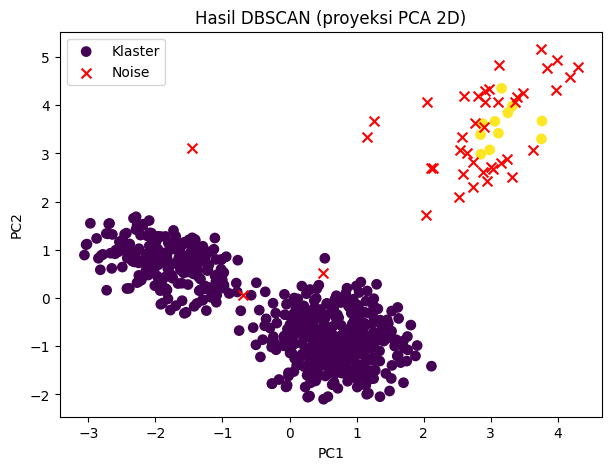

In [8]:
pc = PCA(n_components=2, random_state=42).fit_transform(X_all_s)
mask = df['Cluster_DBSCAN'] == -1

plt.figure(figsize=(7, 5))
plt.scatter(pc[~mask, 0], pc[~mask, 1], c=df.loc[~mask, 'Cluster_DBSCAN'],
            cmap='viridis', s=45, label='Klaster')
plt.scatter(pc[mask, 0], pc[mask, 1], c='red', marker='x', s=50, label='Noise')
plt.title("Hasil DBSCAN (proyeksi PCA 2D)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.show()

DBSCAN dijalankan dengan **seluruh fitur numerik yang dapat digunakan**, yaitu Avg_Credit_Limit, Total_Credit_Cards, Total_visits_bank, Total_visits_online, dan Total_calls_made. Kolom Sl_No dan Customer Key tidak diikutkan karena hanya merupakan identitas nasabah.

Parameter `min_samples = 10` (aturan 2 × jumlah fitur). Nilai `eps` ditentukan dengan elbow method pada **k-distance graph**: jarak ke tetangga ke-10 naik landai pada sebagian besar data (median 0,68; persentil ke-90 0,85), lalu melonjak tajam di bagian akhir kurva. Titik siku berada pada eps ≈ 0,813, tetapi pada nilai ini DBSCAN hanya menghasilkan **1 klaster** (noise 8,18%) sehingga tidak dapat digunakan untuk segmentasi.

Eksplorasi nilai eps menunjukkan DBSCAN sangat sensitif terhadap parameter:

| eps | Jumlah klaster | Noise (%) |
|---|---|---|
| 0,614 | 6 | 34,09 |
| 0,819 | 1 | 8,18 |
| **1,024** | **2** | **6,36** |
| 1,228 | 2 | 1,82 |
| 1,433 | 2 | 0,45 |
| 1,638 | 2 | 0,15 |

Eps yang terlalu kecil memecah data menjadi banyak klaster kecil dengan noise tinggi (eps 0,614: 6 klaster dan 34% noise). Pada eps sekitar 0,82 hanya terbentuk satu klaster. Eps yang terlalu besar (sekitar 1,8 ke atas) menyatukan seluruh data ke dalam satu klaster. Karena itu eps dikoreksi ke nilai terdekat dari titik siku yang menghasilkan minimal 2 klaster, yaitu **eps ≈ 1,024**. Model akhir menghasilkan **2 klaster dan 42 titik noise (6,36%)**:

| Label | Jumlah | Rata-rata limit | Kartu | Kunjungan bank | Kunjungan online | Telepon |
|---|---|---|---|---|---|---|
| Klaster 0 | 607 | 25.703 | 4,4 | 2,56 | 1,92 | 3,79 |
| Klaster 1 | 11 | 157.455 | 8,9 | 0,73 | 10,36 | 1,45 |
| Noise (-1) | 42 | 130.595 | 8,3 | 0,55 | 10,55 | 1,14 |

Klaster 0 adalah nasabah mayoritas dengan limit menengah ke bawah yang sering ke bank dan menelepon. Klaster 1 adalah segmen kecil nasabah premium yang dominan bertransaksi online. Titik noise memiliki karakteristik mirip klaster 1: dari 42 titik noise, 28 berlimit di atas 100 ribu dan 32 memiliki kunjungan online ≥ 8. Artinya sebagian besar noise adalah nasabah premium yang tersebar jarang dan tidak cukup padat untuk membentuk klaster sendiri.

## Soal 6 - Silhouette Score dan Davies-Bouldin Index (DBSCAN)
Titik noise (label -1) dikeluarkan dari perhitungan karena bukan anggota klaster mana pun.

In [9]:
valid = df['Cluster_DBSCAN'] != -1
n_klaster_valid = df.loc[valid, 'Cluster_DBSCAN'].nunique()

if n_klaster_valid >= 2:
    sil_db = silhouette_score(X_all_s[valid], df.loc[valid, 'Cluster_DBSCAN'])
    dbi_db = davies_bouldin_score(X_all_s[valid], df.loc[valid, 'Cluster_DBSCAN'])
    print("=== Tanpa titik noise ===")
    print(f"Silhouette score     : {sil_db:.4f}")
    print(f"Davies-Bouldin Index : {dbi_db:.4f}")

    print("\n=== Dengan noise (label -1 dihitung sebagai kelompok) ===")
    print(f"Silhouette score     : {silhouette_score(X_all_s, df['Cluster_DBSCAN']):.4f}")
    print(f"Davies-Bouldin Index : {davies_bouldin_score(X_all_s, df['Cluster_DBSCAN']):.4f}")
else:
    print("Klaster valid < 2, silhouette dan DBI tidak dapat dihitung. Ubah eps/min_samples.")

=== Tanpa titik noise ===
Silhouette score     : 0.5761
Davies-Bouldin Index : 0.4809

=== Dengan noise (label -1 dihitung sebagai kelompok) ===
Silhouette score     : 0.5028
Davies-Bouldin Index : 2.4378


Evaluasi dihitung tanpa titik noise:

- **Silhouette score = 0,5761**
- **Davies-Bouldin Index = 0,4809**

Silhouette berada pada kisaran 0,5 yang tergolong cukup baik, dan DBI di bawah 1 menunjukkan klaster terpisah dengan baik. Sebagai pembanding, jika noise dihitung sebagai satu kelompok tersendiri, silhouette menjadi 0,5028 dan DBI melonjak menjadi 2,4378, karena kelompok noise tersebar dan berimpitan dengan klaster premium.

Hasil ini perlu dibaca hati-hati. Skor yang baik sebagian besar disebabkan klaster 0 sangat dominan (607 dari 660 nasabah) dan terpisah dari klaster kecil 11 titik. Dibanding K-Means, DBSCAN hanya menghasilkan 2 segmen yang tidak seimbang sehingga kurang informatif untuk membedakan nasabah limit rendah dan menengah. Selain itu, silhouette dan DBI berbasis jarak ke pusat klaster sehingga kurang ideal untuk klaster non-cembung. Evaluasi sebaiknya dikombinasikan dengan persentase noise (6,36%) dan inspeksi visual.